### Setup and Device Selection

In [2]:
%load_ext autoreload
%autoreload 2

import os
import sys
import random
from pathlib import Path

# Add project root to sys.path
PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Reproducibility Seed Configuration
def set_seed(seed: int = 42):
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import numpy as np
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve

import torch
import torch.nn as nn
from torch.utils.data import DataLoader

from src.models import WildfireCNN
from src.dataset import WildfireTensorDataset

# Enforce determinism across all libraries
set_seed(42)

# Device selection fallback chain: CUDA -> MPS -> CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
    print(f"Using NVIDIA GPU (CUDA): {torch.cuda.get_device_name(0)}")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
    print("Using Apple Silicon GPU (Metal Performance Shaders - MPS)")
else:
    device = torch.device("cpu")
    print("No hardware accelerator found. Defaulting to CPU")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Using Apple Silicon GPU (Metal Performance Shaders - MPS)


### Load Extracted Splits

In [3]:
# Set batch size to 256 for balanced GPU utilization on Apple Silicon
BATCH_SIZE = 256

train_dataset = WildfireTensorDataset(
    "../data/processed/tensors/X_train.npy",
    "../data/processed/tensors/y_train.npy"
)

val_dataset = WildfireTensorDataset(
    "../data/processed/tensors/X_val.npy",
    "../data/processed/tensors/y_val.npy"
)

# shuffle=True for training; False for deterministic validation
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE * 2, shuffle=False)

print(f"Train samples : {len(train_dataset):,}")
print(f"Val samples   : {len(val_dataset):,}")

# Quick sanity check on tensor shape and dtype
sample_x, sample_y = train_dataset[0]
print(f"Sample X shape: {sample_x.shape} (dtype: {sample_x.dtype})")
print(f"Sample y shape: {sample_y.shape} (dtype: {sample_y.dtype})")

Train samples : 557,616
Val samples   : 1,388,899
Sample X shape: torch.Size([9, 7, 7]) (dtype: torch.float32)
Sample y shape: torch.Size([1]) (dtype: torch.float32)


### Initialize Model, Loss Function with Imbalance Weight, and Optimizer

In [4]:
# Model & Criterion Setup
model = WildfireCNN().to(device)

# Weight positive class (fire) ~50x to counter background class imbalance
pos_weight = torch.tensor([50.0], device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# AdamW with mild weight decay for regularization
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# Learning rate scheduler: decays LR when validation loss plateaus
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="max", factor=0.5, patience=1
)

print(model)

WildfireCNN(
  (conv1): Conv2d(9, 32, kernel_size=(3, 3), stride=(1, 1))
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
  (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool): AdaptiveAvgPool2d(output_size=(1, 1))
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


### Training and Evaluation Loop with Live Metrics
IMPORTANT: 
* Remember to rename the filename for the directory to prevent overwriting and to maintain distinctions between different model runs.
* The naming convention is as follows: `cnn_baseline_run{number}_{name}.pt`

In [5]:
# Training, Validation, and Metric Tracking Loop
from pathlib import Path

EPOCHS = 10
best_val_pr_auc = 0.0

checkpoint_dir = Path("../models")
checkpoint_dir.mkdir(parents=True, exist_ok=True)
best_model_path = checkpoint_dir / "cnn_baseline_run2_seeded.pt"

# History tracker for evaluation plots
history = {
    "train_loss": [],
    "val_loss": [],
    "val_roc_auc": [],
    "val_pr_auc": []
}

for epoch in range(EPOCHS):
    # ------------------- TRAINING PHASE -------------------
    model.train()
    total_train_loss = 0.0
    
    pbar_train = tqdm(train_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS:02d} [Train]")
    for X_batch, y_batch in pbar_train:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        
        optimizer.zero_grad()
        logits = model(X_batch)
        loss = criterion(logits, y_batch)
        loss.backward()
        optimizer.step()
        
        total_train_loss += loss.item() * len(y_batch)
        pbar_train.set_postfix({"loss": f"{loss.item():.4f}"})
        
    avg_train_loss = total_train_loss / len(train_dataset)
    history["train_loss"].append(avg_train_loss)
    
    # ------------------- VALIDATION PHASE -------------------
    model.eval()
    total_val_loss = 0.0
    val_preds = []
    val_targets = []
    
    pbar_val = tqdm(val_loader, desc=f"Epoch {epoch+1:02d}/{EPOCHS:02d} [Val]")
    with torch.no_grad():
        for X_batch, y_batch in pbar_val:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            
            logits = model(X_batch)
            loss = criterion(logits, y_batch)
            total_val_loss += loss.item() * len(y_batch)
            
            probs = torch.sigmoid(logits)
            val_preds.extend(probs.cpu().numpy())
            val_targets.extend(y_batch.cpu().numpy())
            
    avg_val_loss = total_val_loss / len(val_dataset)
    val_preds = np.array(val_preds).flatten()
    val_targets = np.array(val_targets).flatten()
    
    # Compute Area Under ROC and Precision-Recall Curves
    val_roc_auc = roc_auc_score(val_targets, val_preds)
    val_pr_auc = average_precision_score(val_targets, val_preds)
    
    history["val_loss"].append(avg_val_loss)
    history["val_roc_auc"].append(val_roc_auc)
    history["val_pr_auc"].append(val_pr_auc)
    
    # Step learning rate scheduler based on PR-AUC
    scheduler.step(val_pr_auc)
    current_lr = optimizer.param_groups[0]['lr']
    
    print(
        f"Epoch {epoch+1:02d}/{EPOCHS:02d} Result -> "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f} | "
        f"Val ROC-AUC: {val_roc_auc:.4f} | "
        f"Val PR-AUC: {val_pr_auc:.4f} | "
        f"LR: {current_lr:.6f}"
    )
    
    # Save checkpoint if current epoch achieves peak PR-AUC
    if val_pr_auc > best_val_pr_auc:
        best_val_pr_auc = val_pr_auc
        torch.save(model.state_dict(), best_model_path)
        print(f"  --> Saved new best baseline model to {best_model_path} (PR-AUC: {best_val_pr_auc:.4f})")

print(f"\nTraining complete. Peak Validation PR-AUC: {best_val_pr_auc:.4f}")

Epoch 01/10 [Train]:   0%|          | 0/2179 [00:00<?, ?it/s]

Epoch 01/10 [Val]:   0%|          | 0/2713 [00:00<?, ?it/s]

Epoch 01/10 Result -> Train Loss: 0.0669 | Val Loss: 0.0311 | Val ROC-AUC: 0.9979 | Val PR-AUC: 0.8998 | LR: 0.001000
  --> Saved new best baseline model to ../models/cnn_baseline_run2_seeded.pt (PR-AUC: 0.8998)


Epoch 02/10 [Train]:   0%|          | 0/2179 [00:00<?, ?it/s]

Epoch 02/10 [Val]:   0%|          | 0/2713 [00:00<?, ?it/s]

Epoch 02/10 Result -> Train Loss: 0.0423 | Val Loss: 0.0265 | Val ROC-AUC: 0.9970 | Val PR-AUC: 0.8167 | LR: 0.001000


... (20 outputs left out)

Epoch 09/10 Result -> Train Loss: 0.0210 | Val Loss: 0.0216 | Val ROC-AUC: 0.9987 | Val PR-AUC: 0.9205 | LR: 0.000250
  --> Saved new best baseline model to ../models/cnn_baseline_run2_seeded.pt (PR-AUC: 0.9205)


Epoch 10/10 [Train]:   0%|          | 0/2179 [00:00<?, ?it/s]

Epoch 10/10 [Val]:   0%|          | 0/2713 [00:00<?, ?it/s]

Epoch 10/10 Result -> Train Loss: 0.0199 | Val Loss: 0.0232 | Val ROC-AUC: 0.9987 | Val PR-AUC: 0.9214 | LR: 0.000250
  --> Saved new best baseline model to ../models/cnn_baseline_run2_seeded.pt (PR-AUC: 0.9214)

Training complete. Peak Validation PR-AUC: 0.9214


### Plot and Save Training Curves and Final PR_AUC Curves
IMPORTANT: 
* Remember to rename the filename where you're saving these plots for the directory to prevent overwriting and to maintain distinctions between different model runs.
* The naming convention is as follows: `cnn_baseline_run{number}_{name}_diagnostics.png`

Saved diagnostic plots to: ../outputs/cnn_baseline_run2_seeded_diagnostics.png


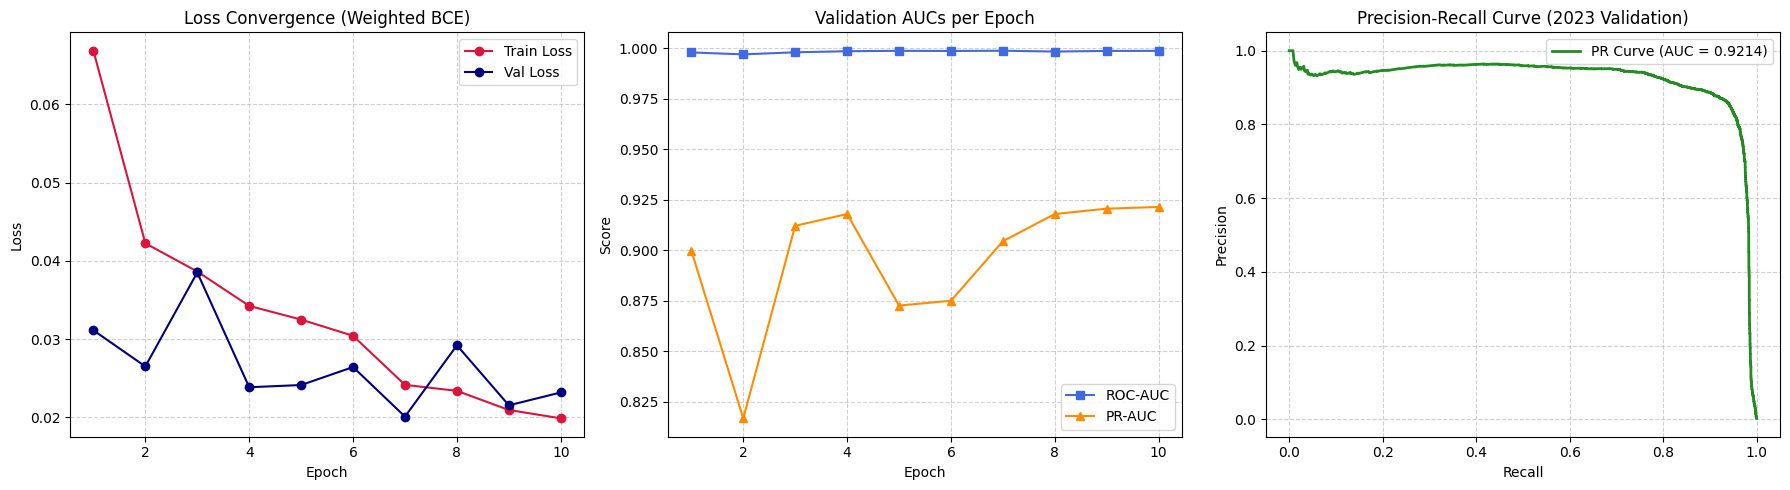

In [8]:
# Diagnostic & Performance Plots
from sklearn.metrics import precision_recall_curve

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Train vs. Validation Loss
axes[0].plot(range(1, EPOCHS + 1), history["train_loss"], marker='o', label="Train Loss", color='crimson')
axes[0].plot(range(1, EPOCHS + 1), history["val_loss"], marker='o', label="Val Loss", color='navy')
axes[0].set_title("Loss Convergence (Weighted BCE)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.6)

# 2. Validation Metrics Over Epochs
axes[1].plot(range(1, EPOCHS + 1), history["val_roc_auc"], marker='s', label="ROC-AUC", color='royalblue')
axes[1].plot(range(1, EPOCHS + 1), history["val_pr_auc"], marker='^', label="PR-AUC", color='darkorange')
axes[1].set_title("Validation AUCs per Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.6)

# 3. Precision-Recall Curve (Final/Best Predictions)
precision, recall, _ = precision_recall_curve(val_targets, val_preds)
axes[2].plot(recall, precision, color="forestgreen", lw=2, label=f"PR Curve (AUC = {val_pr_auc:.4f})")
axes[2].set_title("Precision-Recall Curve (2023 Validation)")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].legend()
axes[2].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()

# Save figure to existing project outputs directory
figures_path = Path("../outputs/cnn_baseline_run2_seeded_diagnostics.png")
plt.savefig(figures_path, dpi=300, bbox_inches="tight")
print(f"Saved diagnostic plots to: {figures_path}")

plt.show()

### Save Metrics JSON

IMPORTANT: 
* Remember to rename the filename for the directory to prevent overwriting and to maintain distinctions between different model runs.
* The naming convention is as follows:
  * For `"model"`: `cnn_baseline_run{number}_{name}`
  * For metrics_path: `cnn_baseline_run{number}_{name}_metrics.json`

In [9]:
import json

outputs_dir = Path("../outputs")

cnn_val_summary = {
    "model": "WildfireCNN_baseline_run2_seeded",
    "run": "run2_seeded",
    "seed": 42,
    "epochs": EPOCHS,
    "best_val_pr_auc": float(best_val_pr_auc),
    "final_val_loss": float(history["val_loss"][-1]),
    "final_val_roc_auc": float(history["val_roc_auc"][-1]),
    "final_val_pr_auc": float(history["val_pr_auc"][-1]),
    "history": history
}

metrics_path = outputs_dir / "cnn_baseline_run2_seeded_validation_metrics.json"
with open(metrics_path, "w") as f:
    json.dump(cnn_val_summary, f, indent=4)

print(f"Saved CNN validation metrics to: {metrics_path}")

Saved CNN validation metrics to: ../outputs/cnn_baseline_run2_seeded_validation_metrics.json
